# Bangkok Transit: what the network and its fares tell you

An analysis of Bangkok's rail and river network: the BTS Skytrain, MRT Blue Line, Airport Rail Link, Gold Line and the Chao Phraya boats.
It uses the same data and fare rules as the route planner in my [Bangkok Guide website](https://tawansir1.github.io/bangkok-travel-guide/), and computes the fastest route and fare for every pair of stations.

**Questions**
1. How big is each line, and where do they connect?
2. Which stations hold the network together?
3. How does each operator charge, and which is cheapest per stop?
4. How much does changing operator cost you?
5. When is a taxi cheaper than the train?
6. What does the whole network look like as a graph?

Fares were checked in November 2026. BTS extension fares and the river ferry are estimates, see *Limits* at the end.

In [12]:
import pandas as pd
import matplotlib.pyplot as plt
import networkx as nx
from pathlib import Path

from transit import Network

net = Network.load("data")
Path("charts").mkdir(exist_ok=True)

COLORS = net.lines["color"].to_dict()
plt.rcParams.update({
    "figure.dpi": 110, "font.size": 10,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.titleweight": "bold", "axes.titlesize": 12, "axes.titlelocation": "left",
})
print(f"{net.stations.code.nunique()} stations and piers, {len(net.links)} links")

117 stations and piers, 124 links


In [13]:
# Fastest route and fare between every pair of stations (about 18 seconds)
trips = net.all_trips()
trips = trips[trips.tickets > 0]          # drop pairs you can simply walk between
print(f"{len(trips):,} trips computed")
trips.head()

13,550 trips computed


,from,to,minutes,fare,tickets,systems,stops,road_km,taxi_clear,taxi_rush
0,A1,A2,7.5,15,1,arl,1,4.6,58,79
1,A1,A3,11.0,20,1,arl,2,9.1,88,129
2,A1,A4,14.5,25,1,arl,3,13.7,119,181
3,A1,A5,18.0,30,1,arl,4,18.2,151,233
4,A1,A6,21.5,35,1,arl,5,22.8,186,288


## 1. Lines and interchanges

,between,walk (min)
0,Mo Chit ↔ Chatuchak Park,6.0
1,Ha Yaek Lat Phrao ↔ Phahon Yothin,5.0
2,Asok ↔ Sukhumvit,5.0
3,Sala Daeng ↔ Si Lom,5.0
4,Bang Wa ↔ Bang Wa,6.0
5,Phaya Thai ↔ Phaya Thai,6.0
6,Phetchaburi ↔ Makkasan,8.0
7,Saphan Taksin ↔ Sathorn Pier,4.0
8,Krung Thon Buri ↔ Krung Thon Buri,4.0
9,Sanam Chai ↔ Tha Tien Pier,9.0


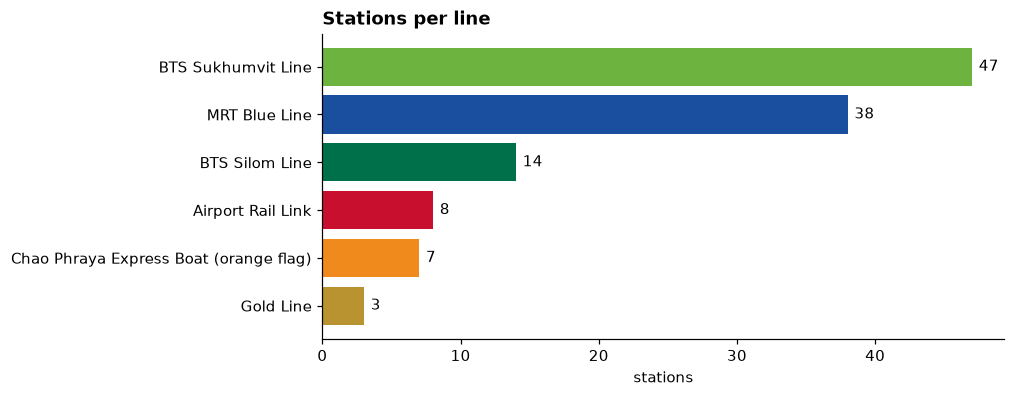

In [14]:
rail = net.stations[~net.stations.line.isin(["ferry"])]
per_line = (rail.groupby("line").code.nunique()
            .rename(index=net.lines["name"]).sort_values())

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.barh(per_line.index, per_line.values,
        color=[COLORS[net.lines.index[net.lines.name == n][0]] for n in per_line.index])
for y, v in enumerate(per_line.values):
    ax.text(v + 0.5, y, str(v), va="center")
ax.set_title("Stations per line")
ax.set_xlabel("stations")
fig.savefig("charts/1_stations_per_line.png", bbox_inches="tight")

walk = net.links[net.links.line == "walk"].copy()
walk["between"] = walk["from"].map(net.name) + "  ↔  " + walk["to"].map(net.name)
walk[["between", "minutes"]].rename(columns={"minutes": "walk (min)"}).reset_index(drop=True)

## 2. Which stations hold the network together?

*Betweenness centrality* is the share of all fastest routes that pass through a station.
A high value means many journeys depend on it, so a closure there hurts the most.

,% of routes
Siam,32.1
Asok,29.0
Phrom Phong,26.4
Phaya Thai,25.8
Thong Lo,25.2
Sala Daeng,24.6
Ekkamai,24.0
Sukhumvit,23.9
Ha Yaek Lat Phrao,23.8
Ratchathewi,23.6


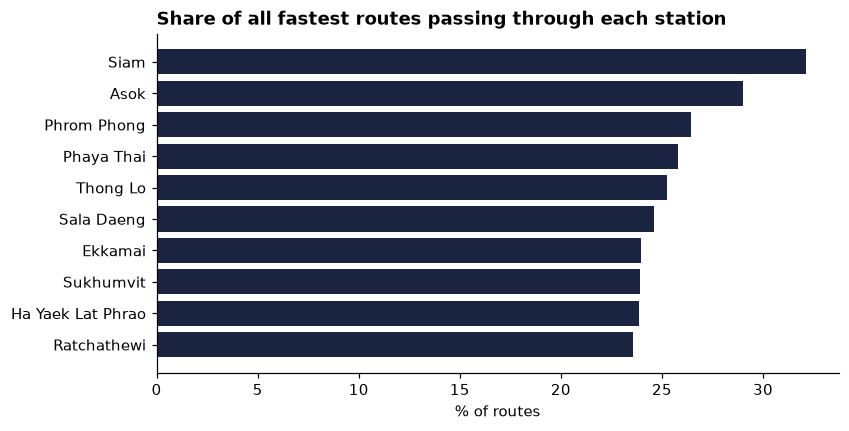

In [15]:
g = net.graph()
for a, b, d in g.edges(data=True):          # walking transfers include the platform wait
    if d["line"] == "walk":
        d["minutes"] += 4

bc = nx.betweenness_centrality(g, weight="minutes", normalized=True)
central = (pd.Series(bc, name="betweenness").sort_values(ascending=False)
           .head(10).rename(index=net.name))

fig, ax = plt.subplots(figsize=(8, 4))
ax.barh(central.index[::-1], central.values[::-1] * 100, color="#1b2440")
ax.set_title("Share of all fastest routes passing through each station")
ax.set_xlabel("% of routes")
fig.savefig("charts/2_central_stations.png", bbox_inches="tight")
(central * 100).round(1).to_frame("% of routes")

In [16]:
# What if the line is blocked at one station (e.g. a breakdown)?
# Trains can't pass that point, so we remove the station from the graph.
base = dict(nx.all_pairs_dijkstra_path_length(g, weight="minutes"))
nodes = list(g.nodes)
pairs = len(nodes) * (len(nodes) - 1)

def closure(code):
    h = g.copy(); h.remove_node(code)
    after = dict(nx.all_pairs_dijkstra_path_length(h, weight="minutes"))
    lost, extra, n = 0, 0.0, 0
    for a in h.nodes:
        for b in h.nodes:
            if a == b: continue
            if b not in after[a]: lost += 1
            else: extra += after[a][b] - base[a][b]; n += 1
    return {"station": net.name[code],
            "trips impossible": lost,
            "% impossible": round(100 * lost / pairs, 1),
            "avg extra min (other trips)": round(extra / n, 1)}

test = ["CEN", "E4", "N2", "S2", "N8", "BL22"]
pd.DataFrame([closure(c) for c in test])

,station,trips impossible,% impossible,avg extra min (other trips)
0,Siam,230,1.7,4.3
1,Asok,3686,27.2,0.1
2,Phaya Thai,0,0.0,3.6
3,Sala Daeng,0,0.0,5.2
4,Mo Chit,0,0.0,2.9
5,Sukhumvit,0,0.0,2.5


## 3. How each operator charges

,BTS (city section),MRT Blue Line,Airport Rail Link
stops,,,
1,17.0,17,15.0
3,28.0,22,25.0
5,35.0,27,35.0
7,43.0,32,45.0


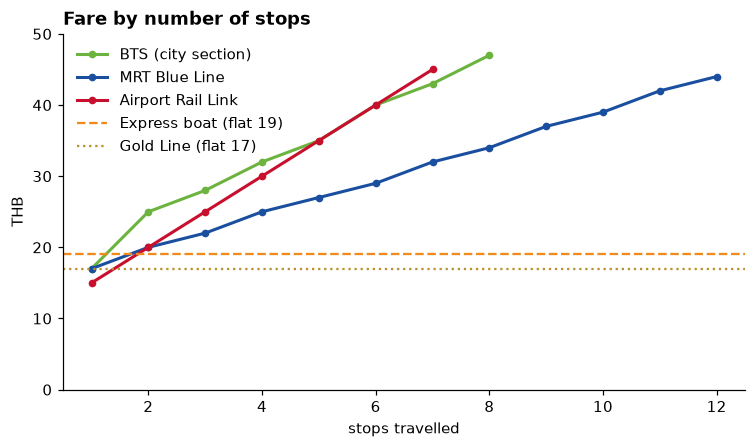

In [17]:
tables = {"bts_core": "BTS (city section)", "mrt_blue": "MRT Blue Line",
          "arl": "Airport Rail Link"}
colors = {"bts_core": COLORS["sukhumvit"], "mrt_blue": COLORS["blue"], "arl": COLORS["arl"]}
f = net.fares

fig, ax = plt.subplots(figsize=(8, 4.2))
for t, label in tables.items():
    d = f[f.table == t]
    ax.plot(d.stops, d.fare_thb, marker="o", ms=4, lw=2, label=label, color=colors[t])
ax.axhline(19, color=COLORS["boat"], ls="--", lw=1.5, label="Express boat (flat 19)")
ax.axhline(17, color=COLORS["gold"], ls=":", lw=1.5, label="Gold Line (flat 17)")
ax.set_title("Fare by number of stops")
ax.set_xlabel("stops travelled"); ax.set_ylabel("THB")
ax.set_xlim(0.5, 12.5); ax.set_ylim(0, 50)
ax.legend(frameon=False, loc="upper left")
fig.savefig("charts/3_fare_curves.png", bbox_inches="tight")

compare = pd.DataFrame({label: f[f.table == t].set_index("stops").fare_thb
                        for t, label in tables.items()}).loc[[1, 3, 5, 7]]
compare.index.name = "stops"
compare

## 4. The cost of changing operator

BTS, MRT and the Airport Rail Link are separate companies, so every change means a new ticket and a new starting fare.
The second table imagines a single ticket for the whole trip, priced with the MRT table on the total number of stops (a hypothetical common fare, not a real one yet).

,trips,median_fare,median_stops,share
tickets,,,,
1,6325,45.0,11.0,46.7
2,6410,69.0,13.0,47.3
3+,815,92.0,15.0,6.0


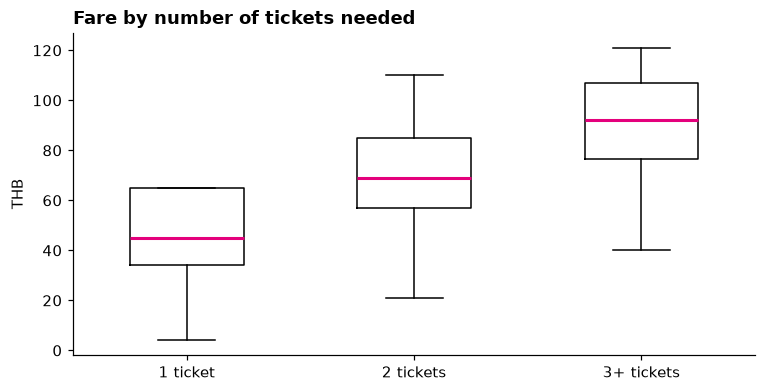

In [18]:
trips["tickets_group"] = trips.tickets.clip(upper=3).map({1: "1", 2: "2", 3: "3+"})
by_tickets = (trips.groupby("tickets_group")
              .agg(trips=("fare", "size"), median_fare=("fare", "median"),
                   median_stops=("stops", "median"))
              .assign(share=lambda d: (100 * d.trips / d.trips.sum()).round(1)))

fig, ax = plt.subplots(figsize=(8, 3.8))
data = [trips.loc[trips.tickets_group == k, "fare"] for k in by_tickets.index]
ax.boxplot(data, tick_labels=[f"{k} ticket{'' if k == '1' else 's'}" for k in by_tickets.index],
           widths=0.5, showfliers=False, medianprops={"color": "#e4007c", "lw": 2})
ax.set_title("Fare by number of tickets needed")
ax.set_ylabel("THB")
fig.savefig("charts/4_fare_by_tickets.png", bbox_inches="tight")
by_tickets.rename_axis("tickets")

In [19]:
mrt = f[f.table == "mrt_blue"].set_index("stops").fare_thb
single = trips.stops.clip(lower=1).map(lambda s: mrt[min(s, mrt.index.max())])
trips["single_ticket"] = single
multi = trips[trips.tickets > 1]
saving = multi.fare - multi.single_ticket
print(f"Trips that need 2+ tickets: {len(multi):,} ({100*len(multi)/len(trips):.0f}% of all)")
print(f"Median fare today: {multi.fare.median():.0f} THB")
print(f"Median with one ticket: {multi.single_ticket.median():.0f} THB")
print(f"Median saving: {saving.median():.0f} THB ({100*(saving/multi.fare).median():.0f}%)")

Trips that need 2+ tickets: 7,225 (53% of all)
Median fare today: 70 THB
Median with one ticket: 44 THB
Median saving: 29 THB (44%)


## 5. When is a taxi cheaper?

Taxi fares use the Bangkok meter (35 THB for the first km, then 6.50–10.50 THB per km) over an estimated road distance.
*Rush hour* adds 3 THB per minute stuck in traffic. Taxi fares are per car, so the comparison changes when you split it with friends.

,"taxi cheaper, clear road","taxi cheaper, rush hour"
people,,
1,0%,0%
2,16%,2%
3,60%,20%
4,87%,47%


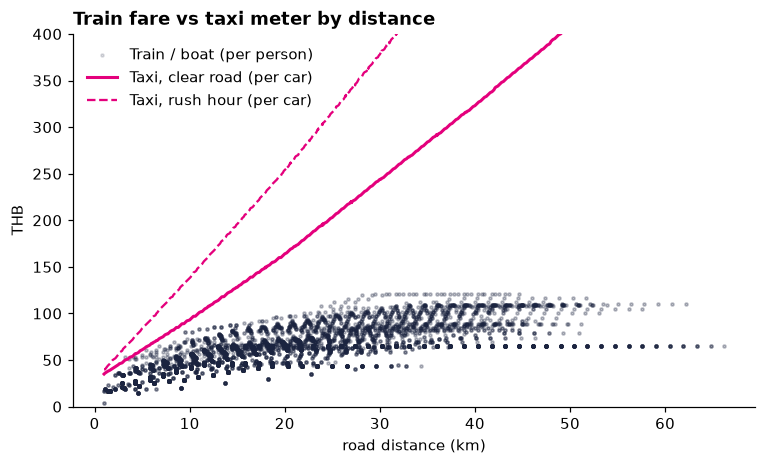

In [20]:
fig, ax = plt.subplots(figsize=(8, 4.4))
ax.scatter(trips.road_km, trips.fare, s=4, alpha=0.15, color="#1b2440", label="Train / boat (per person)")
km = trips.sort_values("road_km")
ax.plot(km.road_km, km.taxi_clear, color="#e4007c", lw=2, label="Taxi, clear road (per car)")
ax.plot(km.road_km, km.taxi_rush, color="#e4007c", lw=1.5, ls="--", label="Taxi, rush hour (per car)")
ax.set_title("Train fare vs taxi meter by distance")
ax.set_xlabel("road distance (km)"); ax.set_ylabel("THB")
ax.set_ylim(0, 400); ax.legend(frameon=False)
fig.savefig("charts/5_train_vs_taxi.png", bbox_inches="tight")

rows = []
for people in [1, 2, 3, 4]:
    rows.append({"people": people,
                 "taxi cheaper, clear road": f"{100*(trips.taxi_clear/people < trips.fare).mean():.0f}%",
                 "taxi cheaper, rush hour": f"{100*(trips.taxi_rush/people < trips.fare).mean():.0f}%"})
pd.DataFrame(rows).set_index("people")

In [21]:
# Cost per person by distance: median train fare vs a shared taxi on a clear road
bins = pd.cut(trips.road_km, [0, 5, 10, 20, 30, 70], labels=["0–5 km", "5–10", "10–20", "20–30", "30+"])
per_person = trips.groupby(bins, observed=True).agg(
    train=("fare", "median"), taxi=("taxi_clear", "median"))
for p in [2, 3, 4]:
    per_person[f"taxi ÷ {p}"] = per_person.taxi / p
per_person.drop(columns="taxi").round(0).astype(int).rename_axis("road distance")

,train,taxi ÷ 2,taxi ÷ 3,taxi ÷ 4
road distance,,,,
0–5 km,22,24,16,12
5–10,39,39,26,20
10–20,56,63,42,32
20–30,65,99,66,50
30+,82,152,101,76


## 6. The network as a graph

A schematic drawn from the links alone (no map coordinates), coloured by line. Dotted grey lines are walking transfers.

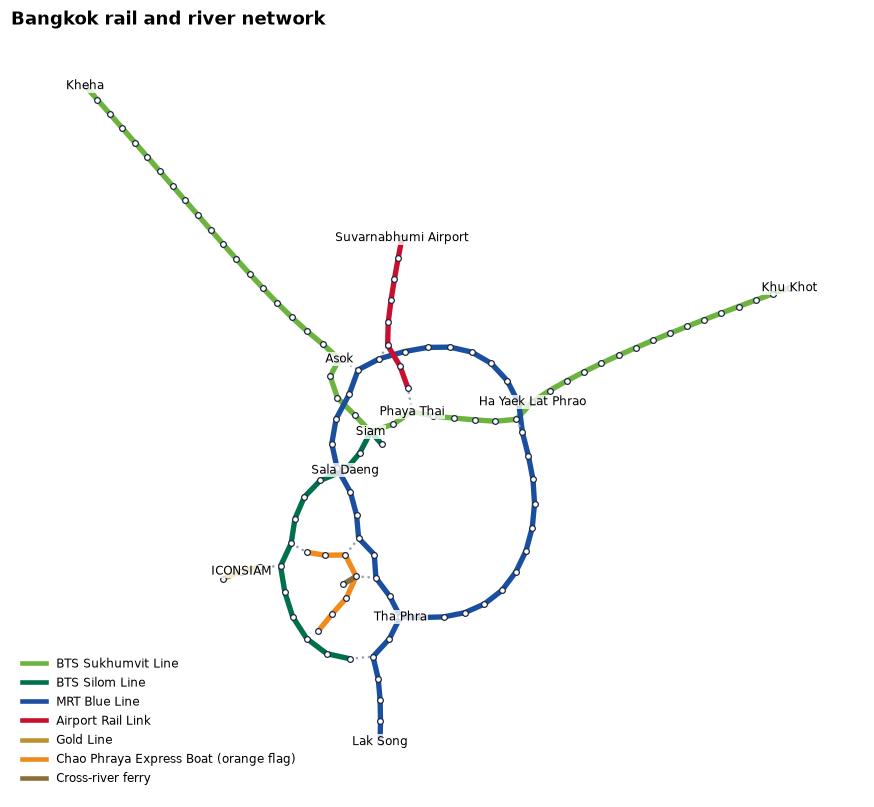

In [22]:
pos = nx.kamada_kawai_layout(g, weight=None)
fig, ax = plt.subplots(figsize=(10, 9))
for line, color in COLORS.items():
    edges = [(a, b) for a, b, d in g.edges(data=True) if d["line"] == line]
    style = "dotted" if line == "walk" else "solid"
    nx.draw_networkx_edges(g, pos, edgelist=edges, edge_color=color, width=1.5 if line == "walk" else 3.5, style=style, ax=ax)
nx.draw_networkx_nodes(g, pos, node_size=14, node_color="white", edgecolors="#1b2440", linewidths=0.8, ax=ax)
show = ["CEN", "E4", "N2", "S2", "N9", "A1", "N24", "E23", "BL38", "BL01"]
labels = {c: net.name[c] for c in show} | {"G2": "ICONSIAM"}
nx.draw_networkx_labels(g, pos, labels=labels, font_size=8, ax=ax,
                        bbox={"fc": "white", "ec": "none", "alpha": 0.8, "pad": 0.5})
handles = [plt.Line2D([], [], color=COLORS[k], lw=3, label=net.lines.at[k, "name"]) for k in COLORS if k != "walk"]
ax.legend(handles=handles, frameon=False, loc="lower left", fontsize=8)
ax.set_title("Bangkok rail and river network")
ax.axis("off")
fig.savefig("charts/6_network.png", bbox_inches="tight")

## Findings

1. **The BTS Sukhumvit Line and MRT Blue Line carry the network.** Together they have 85 of the 117 stations and piers. There are 12 interchanges, and all but Siam need a walk of 4–10 minutes between separate stations.
2. **Siam is the busiest junction**: about a third (32%) of all fastest routes pass through it. The next most central stations are all on the Sukhumvit Line east of Siam (Asok, Phrom Phong, Thong Lo), because that long branch has only one link to the rest of the network.
3. **That branch is the weak point.** If the line is blocked at Asok, 27% of all trips become impossible: the 19 stations from Phrom Phong to Kheha are cut off. Blocking Siam only cuts off National Stadium (2% of trips). Blocking Sala Daeng, Phaya Thai or Mo Chit cuts off nothing, but every trip gets 3–5 minutes longer on average, because the loop of the Blue Line gives another way round.
4. **The MRT is the cheapest per stop.** Five stops cost 27 THB on the MRT but 35 THB on the BTS or the Airport Rail Link, about 30% more. The flat-fare Gold Line (17) and express boat (19) are the cheapest of all for any distance.
5. **Changing operator is expensive.** 53% of all trips need two or more tickets. The median fare is 45 THB with one ticket, 69 THB with two and 92 THB with three or more. If the whole trip were one ticket priced on the MRT table, the median multi-ticket trip would fall from 70 to 44 THB, a saving of 44%. This is the case for the common ticket Bangkok has been planning.
6. **Alone, the train always wins.** A metered taxi is never cheaper than the train for one person, even on a clear road. Shared, it changes: with 3 people a taxi is cheaper for 60% of trips on a clear road, and with 4 people for 87%. In rush hour these fall to 20% and 47%, so for groups the time of day matters more than the distance.

## Limits
- Fares are adult single-journey prices checked in November 2026. BTS extension fares and the river ferry are estimates; other fares follow the operators' published tables.
- Travel times assume 2.5 minutes per stop and a 4-minute wait each time you board. Real times vary.
- Taxi distance is estimated from the rail distance (×1.2), not from real roads, and ignores expressway tolls.
- Only the BTS, MRT Blue Line, Airport Rail Link, Gold Line and orange-flag boat are included. The Purple, Pink, Yellow and Red lines are not.